# GP-C: latent physiology plus an independent flow residual

GP-C changes the semantics of the observation model:

\[
y=f+\epsilon,\qquad f\sim GP(m,K),\qquad \epsilon=T_\psi(z),\quad z\sim\mathcal N(0,I).
\]

Here the GP and the flow represent separate additive components. This creates an inference capability that GP-B does not provide directly: we can inspect the posterior physiology \(f(t)\) separately from the residual distribution.

We now run with `FAST_MODE=True`: `data/toy` for 5 epochs. Full mode (`False`) remains available: `data/synthetic` for 10 epochs. Both modes use CUDA when available and otherwise CPU. All training patients are used; validation and test patients remain separate. Preprocessing is fitted only on the training split.

**Clinical input encoding used throughout these models.** Categories use small learned embeddings: sex, employment, record kind and event type use two coordinates; marital status and history-variable identity use three, while GP query-output identity uses two. Missing/unseen categories are explicit. A category that does not apply to a token uses a zero padding embedding. Adapter indicators are decoded to IDs before neural computation. Physiological values remain training-standardised, with explicit missingness and known-value flags. With small vocabularies, embeddings provide a compact representation; a one-hot vector followed by a linear projection already learns category vectors, so this change does not automatically improve predictions.

Age supplies a **learned continuous absolute-age encoding**, rather than a raw content feature or a sinusoidal code. A small two-layer network maps age in years into the model's hidden dimension:

\[
\mathrm{PE}_\omega(a)=W_2\tanh\!\left(W_1\frac{a}{100}+b_1\right)+b_2.
\]

History tokens add this encoding after their learned content projection. TPP-A reconstructs record ages from entry age and accumulated IATs; dynamic TPPs and GP histories use recorded ages. Equal-age records share an encoding, while the causal attention mask still prevents attending to later records. Each conditioning network replaces age scalars with learned age encodings and categorical indicators with embeddings. All encoding parameters are trained with the model. Duration/IAT inputs retain their log scaling.

The GP still uses actual age differences as its continuous covariance coordinate; output IDs select the covariance matrix. Its neural mean, feature maps and flows receive learned age and output embeddings. This removes imposed periodicity, but does not guarantee reliable extrapolation or a biologically correct ageing trajectory.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
from lifetime_clinical.tutorials.experiments import load_toy,gp_data,fit_gp_c,representative_gp_block
from lifetime_clinical.visualization import plot_fit_history,plot_sampled_predictive_density,plot_residual_decomposition
from lifetime_clinical.data.preprocessing import VARIABLES

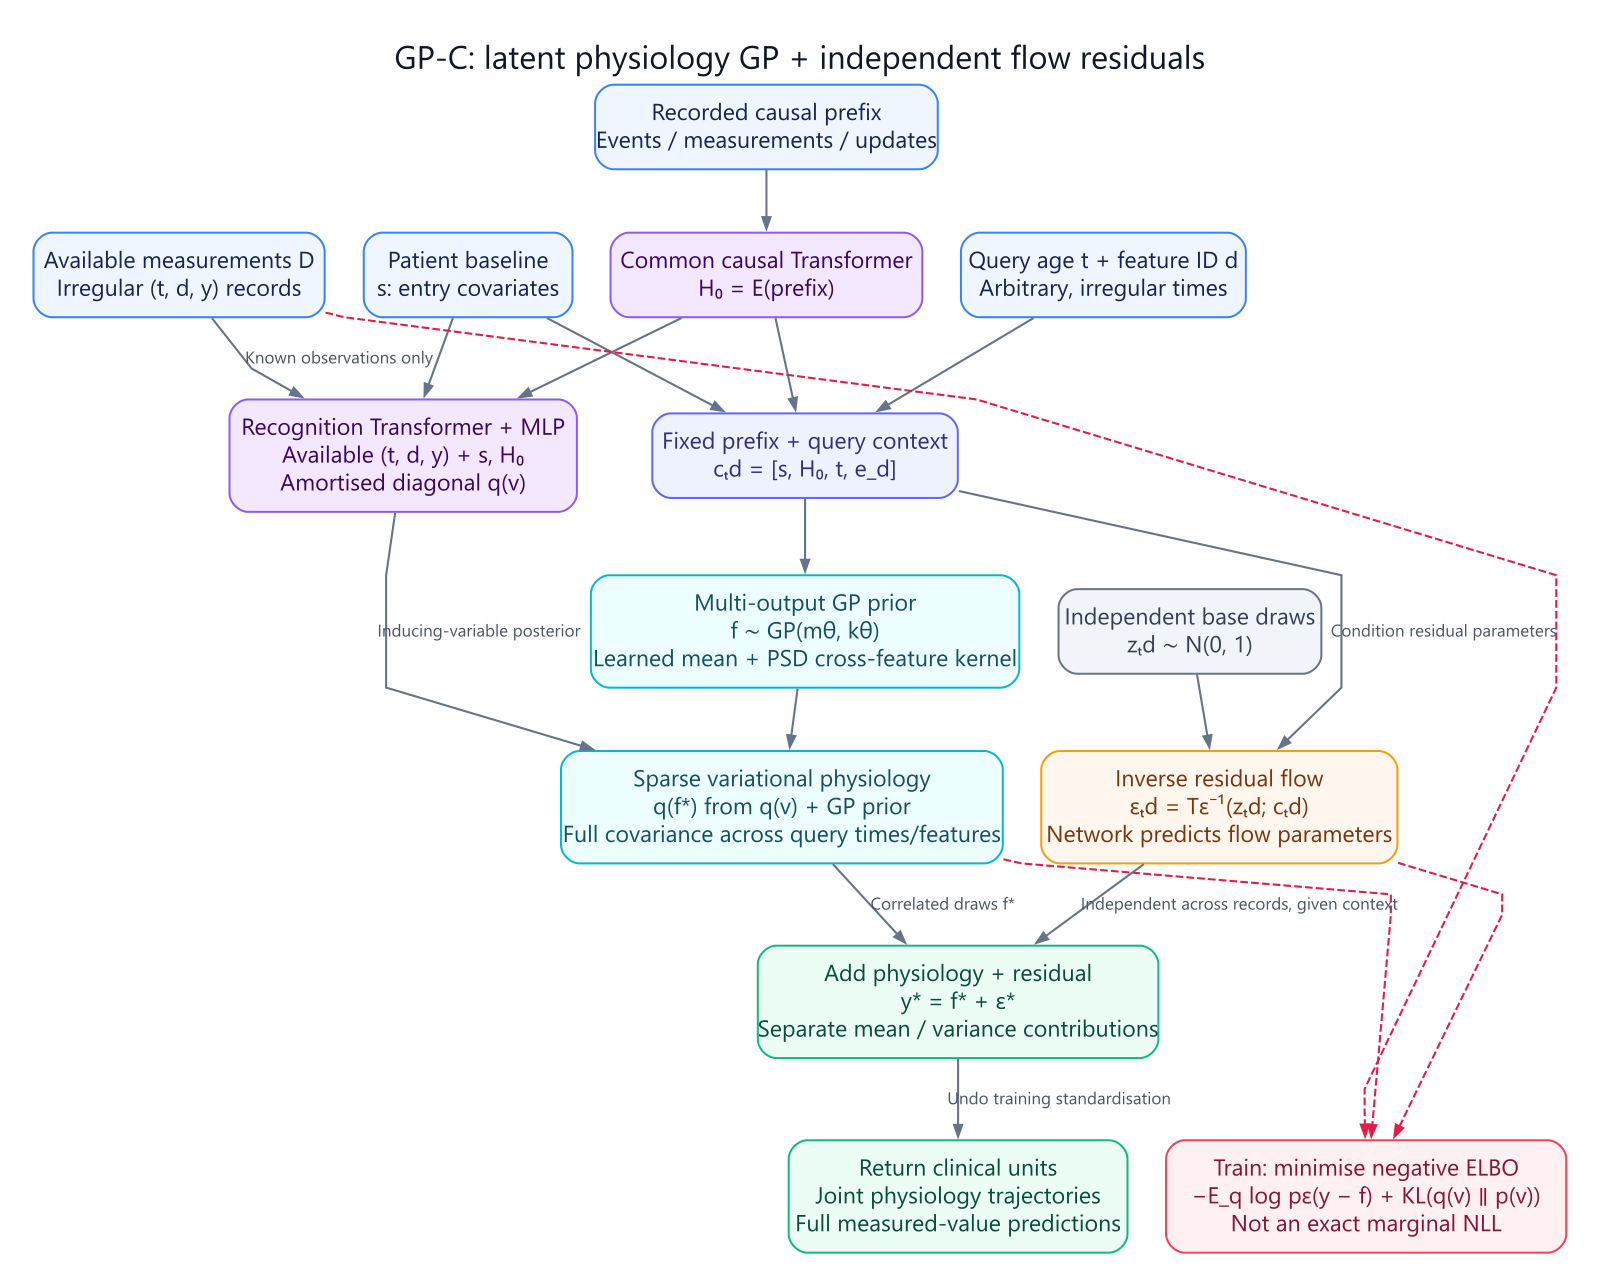

In [2]:
from IPython.display import display
import base64
# GP-C: inputs → outputs
display({
    'image/svg+xml': (ROOT / 'diagrams/gp_c.svg').read_text(encoding='utf-8'),
    'image/png': base64.b64encode((ROOT / 'diagrams/gp_c.png').read_bytes()).decode('ascii'),
}, raw=True)

Dataset: 130 patients; GP blocks: {'train': 97, 'validation': 20, 'test': 10}
Training 5 epochs on cpu


Completed epochs: 5


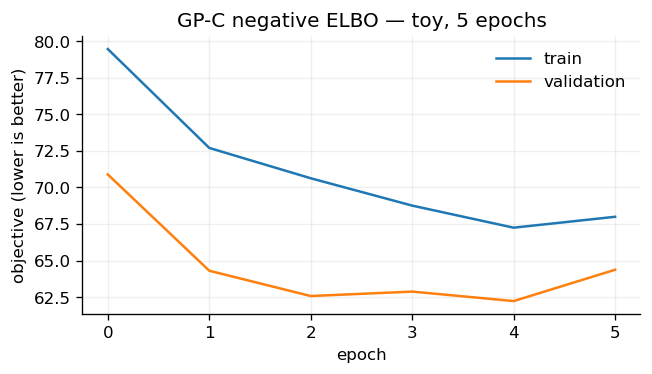

In [3]:
import torch
FAST_MODE=True
EPOCHS=5 if FAST_MODE else 10
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
DATA_DIR=ROOT/"data"/("toy" if FAST_MODE else "synthetic")
dataset,splits,pre=load_toy(DATA_DIR)
blocks=gp_data(dataset,splits,pre,history_fraction=.25)
conditioning,heldout=representative_gp_block(blocks["test"],min_panels=5)
print("Dataset:",len(dataset.patients),"patients; GP blocks:",{k:len(v) for k,v in blocks.items()})
print("Training",EPOCHS,"epochs on",DEVICE,flush=True)
gp_c=fit_gp_c(blocks,epochs=EPOCHS,device=DEVICE)
print("Completed epochs:",gp_c.fit_history[-1]["epoch"],flush=True)
fig,ax=plt.subplots(figsize=(6,3)); plot_fit_history(gp_c,ax,title=f"GP-C negative ELBO — {DATA_DIR.name}, {EPOCHS} epochs"); plt.show()


## Why the objective is different

Conditioned on \(f\), the flow residual likelihood is tractable:

\[
p(y\mid f)=p_{Flow}(y-f).
\]

But the marginal requires

\[
p(y)=\int p_{Flow}(y-f)p_{GP}(f)df,
\]

which is not closed form for a general nonlinear flow. GP-C therefore uses variational GP inference and maximises an ELBO,

\[
\mathcal L_{ELBO}
=\mathbb E_{q(f)}[\log p_{Flow}(y-f)]
-KL[q(u)\|p(u)].
\]

The notebook reports this distinction explicitly; its training objective should not be compared numerically to an exact GP marginal NLL as if they were identical quantities.

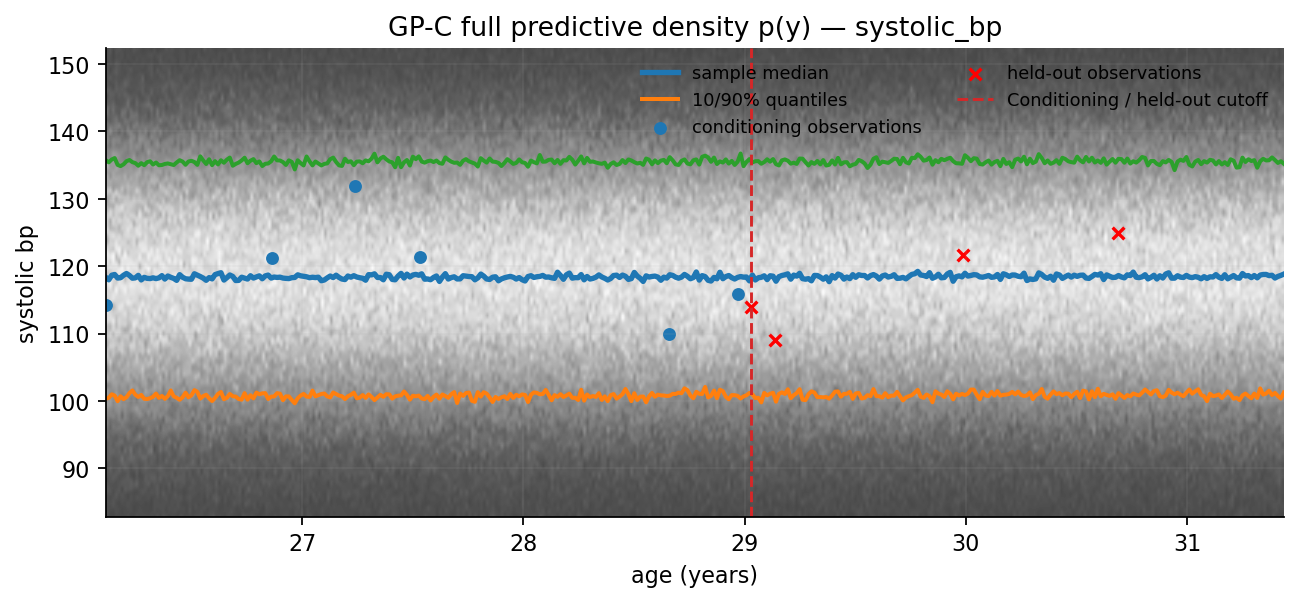

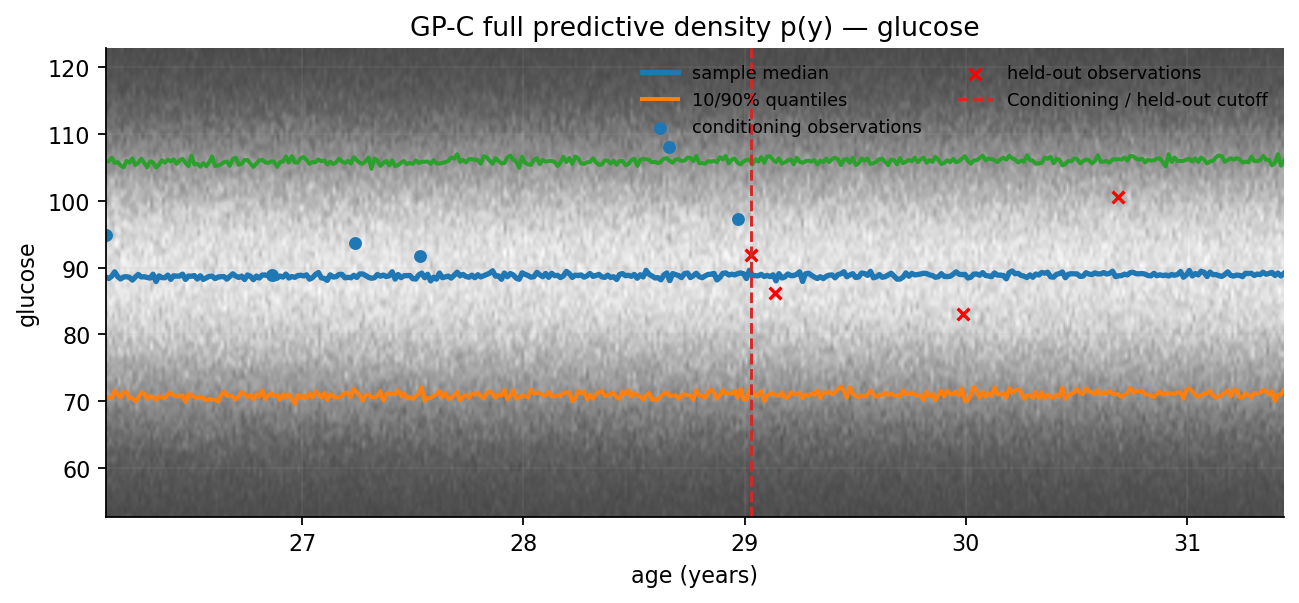

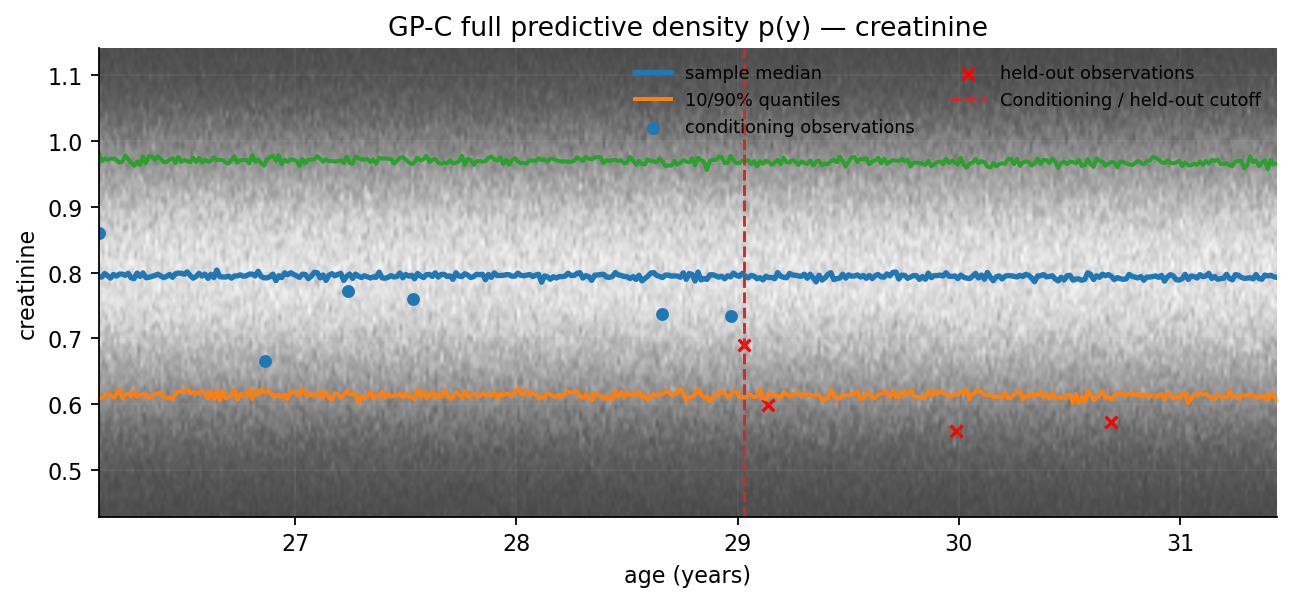

In [4]:
lo=min(conditioning.ages.min(),heldout.ages.min())*100
hi=max(conditioning.ages.max(),heldout.ages.max())*100+.75
cutoff_age=float(heldout.ages.min())*100
age_grid=np.linspace(lo,hi,400)
for vid,v in enumerate(VARIABLES):
    fig,ax=plt.subplots(figsize=(9.5,3.8),dpi=160)
    plot_sampled_predictive_density(gp_c,conditioning,heldout,vid,age_grid,
                                    ax=ax,n_samples=3000,bins=220,cmap="Greys_r",seed=40+vid,
                                    title=f"GP-C full predictive density p(y) — {v}")
    for collection in ax.collections:
        if collection.get_label()=="held-out observations":
            collection.set_color("red")
    ax.axvline(cutoff_age,color="tab:red",linestyle="--",linewidth=1.3,
               label="Conditioning / held-out cutoff")
    ax.legend(frameon=False,ncol=2,fontsize=8)
    plt.show()

The first view deliberately treats physiology and residual uncertainty together: it is the distribution of the **actual future observation** \(y\). Now we use the model-specific decomposition.

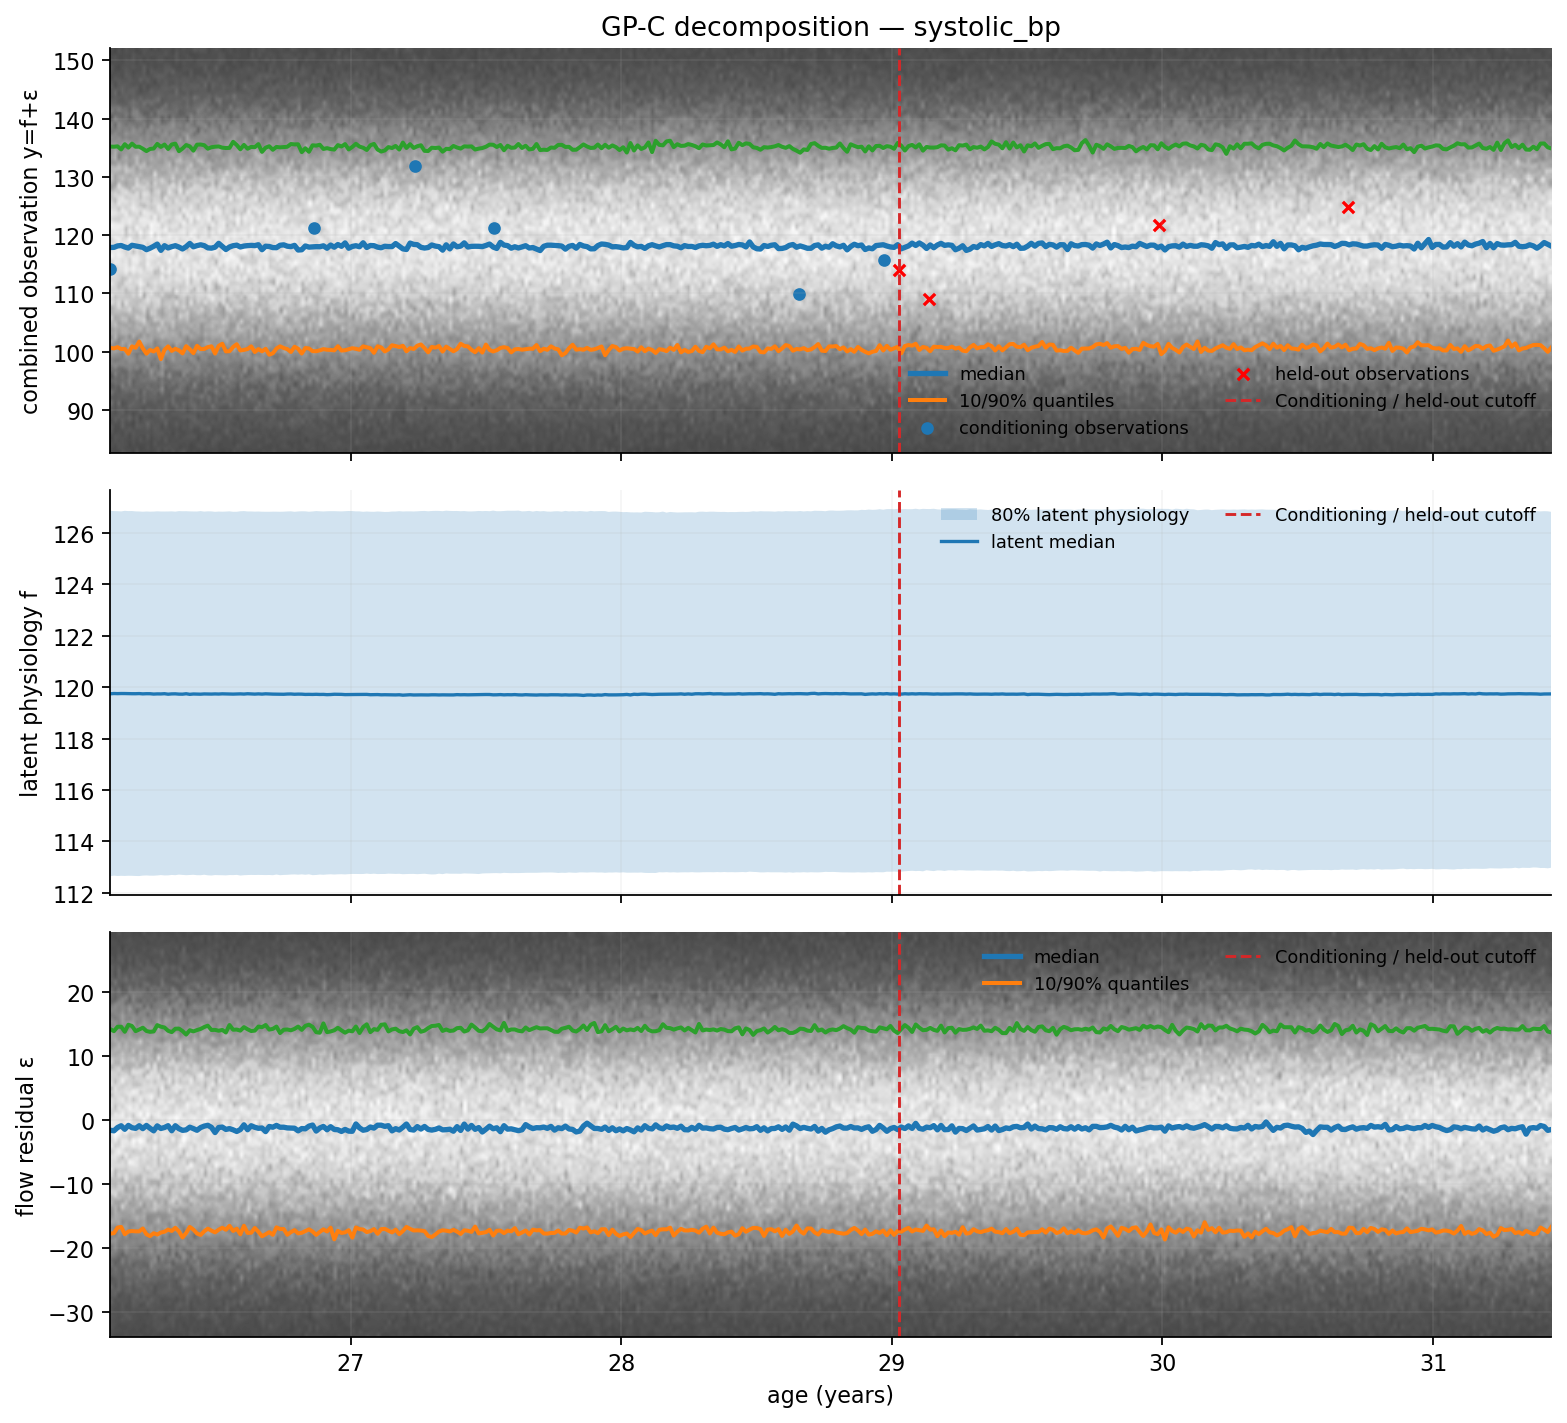

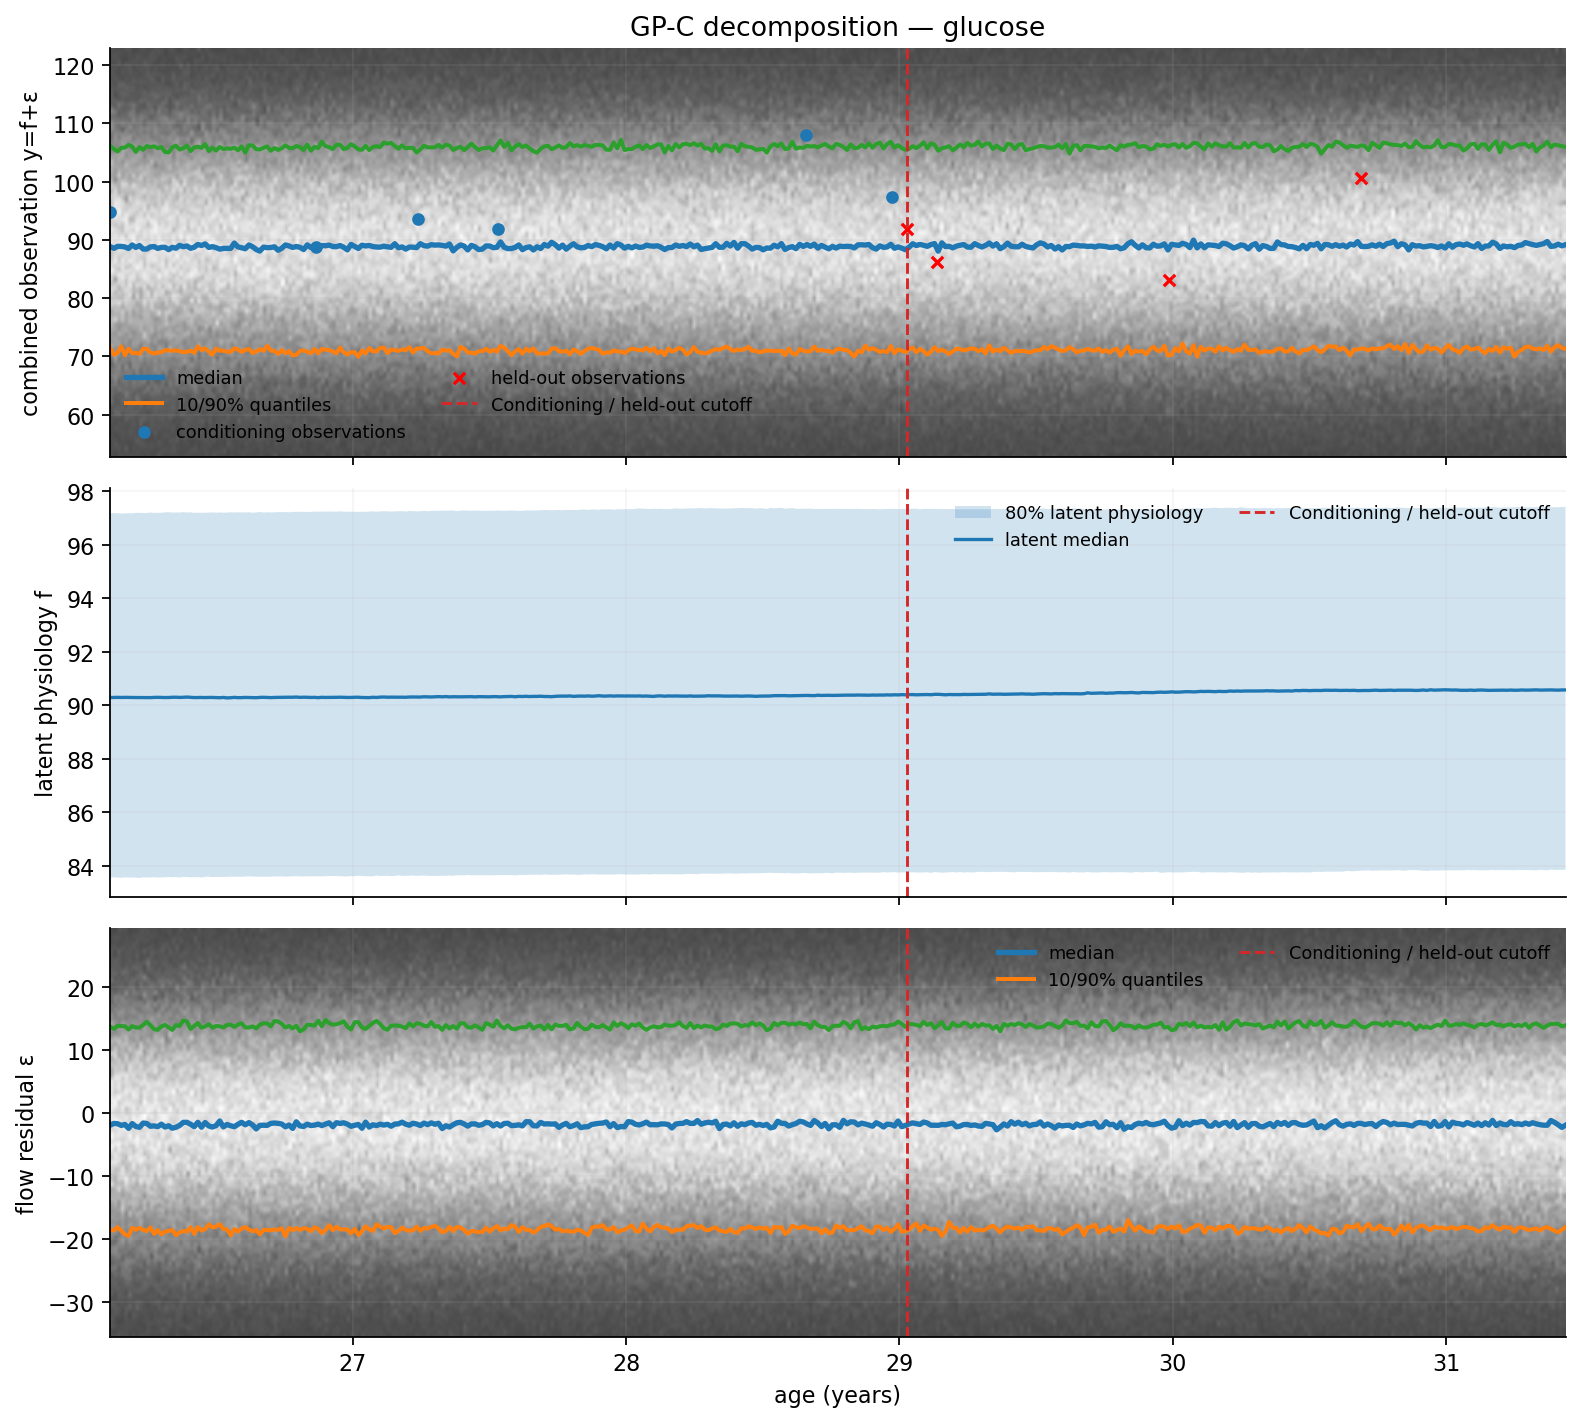

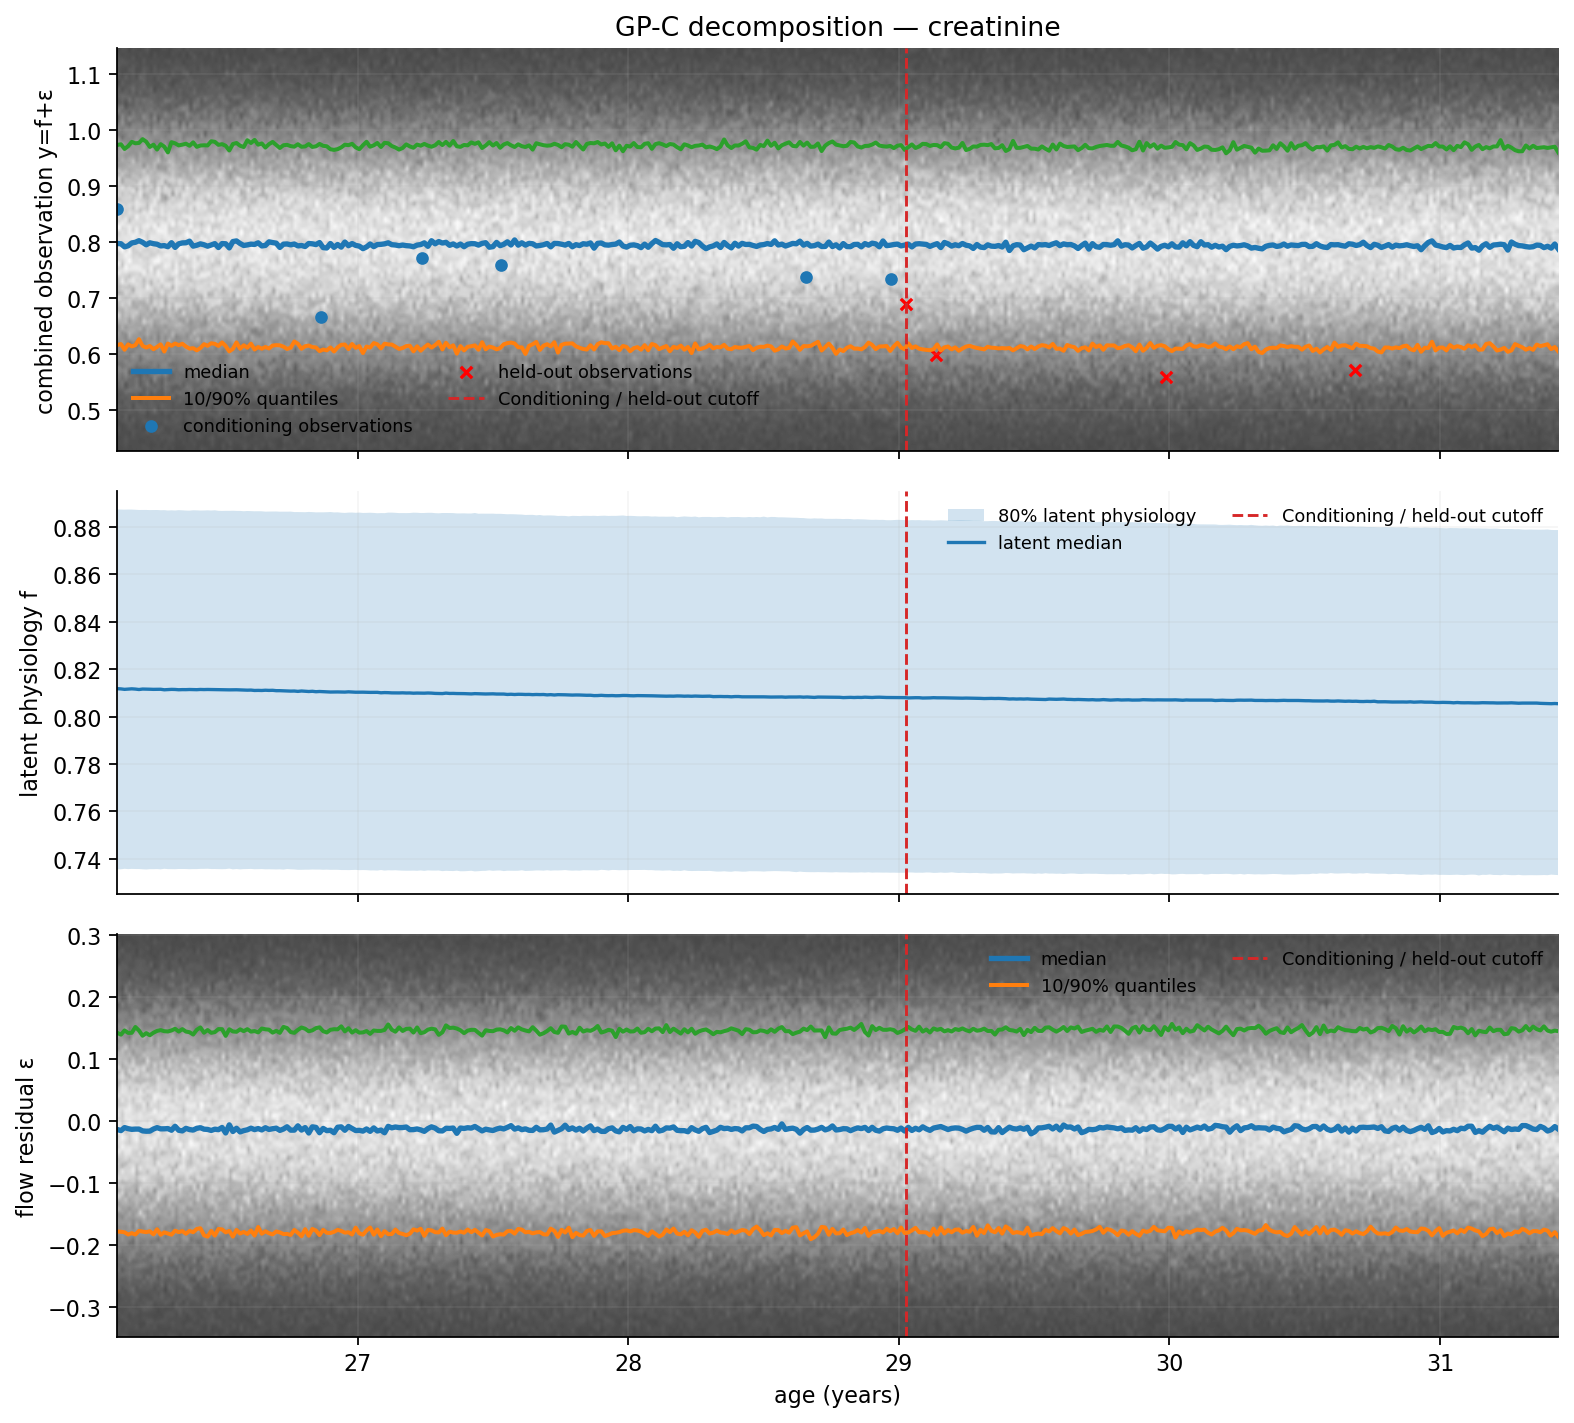

In [5]:
for vid,v in enumerate(VARIABLES):
    fig,axes=plt.subplots(3,1,figsize=(10,9),sharex=True,dpi=160)
    plot_residual_decomposition(gp_c,conditioning,heldout,vid,age_grid,axes=axes,
                               n_samples=3000,bins=220,cmap="Greys_r",seed=60+vid,
                               title=f"GP-C decomposition — {v}")
    for collection in axes[0].collections:
        if collection.get_label()=="held-out observations":
            collection.set_color("red")
    for ax in axes:
        ax.axvline(cutoff_age,color="tab:red",linestyle="--",linewidth=1.3,
                   label="Conditioning / held-out cutoff")
        ax.legend(frameon=False,ncol=2,fontsize=8)
    plt.tight_layout(); plt.show()

For every feature we can now inspect three different objects:

1. \(p(y_d(t)\mid D)\): total predictive observation uncertainty;
2. \(p(f_d(t)\mid D)\): latent GP physiology;
3. \(p(\epsilon_d(t)\mid D)\): flow residual.

This decomposition is a **model assumption**, not automatic causal identification. Without additional constraints, the GP and residual can trade off which component explains persistent structure. Interpreting the residual as a literal clinical anomaly therefore requires extra identifiability/regularisation work.

## How physiology and residuals contribute to the forecast

The separate density panels above show the components, but their quantiles do not simply add. To see their contributions directly, we now forecast **to the right of the conditioning cutoff** and decompose the predictive mean and variance:

\[
E[y\mid H]=E[f\mid H]+E[\epsilon\mid H],
\qquad
\operatorname{Var}(y\mid H)=\operatorname{Var}(f\mid H)+\operatorname{Var}(\epsilon\mid H).
\]

The variance identity uses this implementation's independent future residual and variational GP draws conditional on the observed history and query context. In a more general model, a covariance term would also be needed.

On the **left**, the blue line is the physiology mean and the black line is the observation mean. The orange gap between them is the signed residual mean: it can shift predictions up or down, and is not an uncertainty interval. The clinical-unit offset belongs to physiology; residuals are expressed as additive deviations without that offset.

On the **right**, stacked blue and orange areas show the physiology and residual variance contributions, with their total in black. A residual can contribute substantial uncertainty even when its mean is nearly zero. These are model-based contributions, not identified biological causes or a reconstruction of the realized residual at each held-out point. Means and residual variances use the forecast's numerical quadrature.

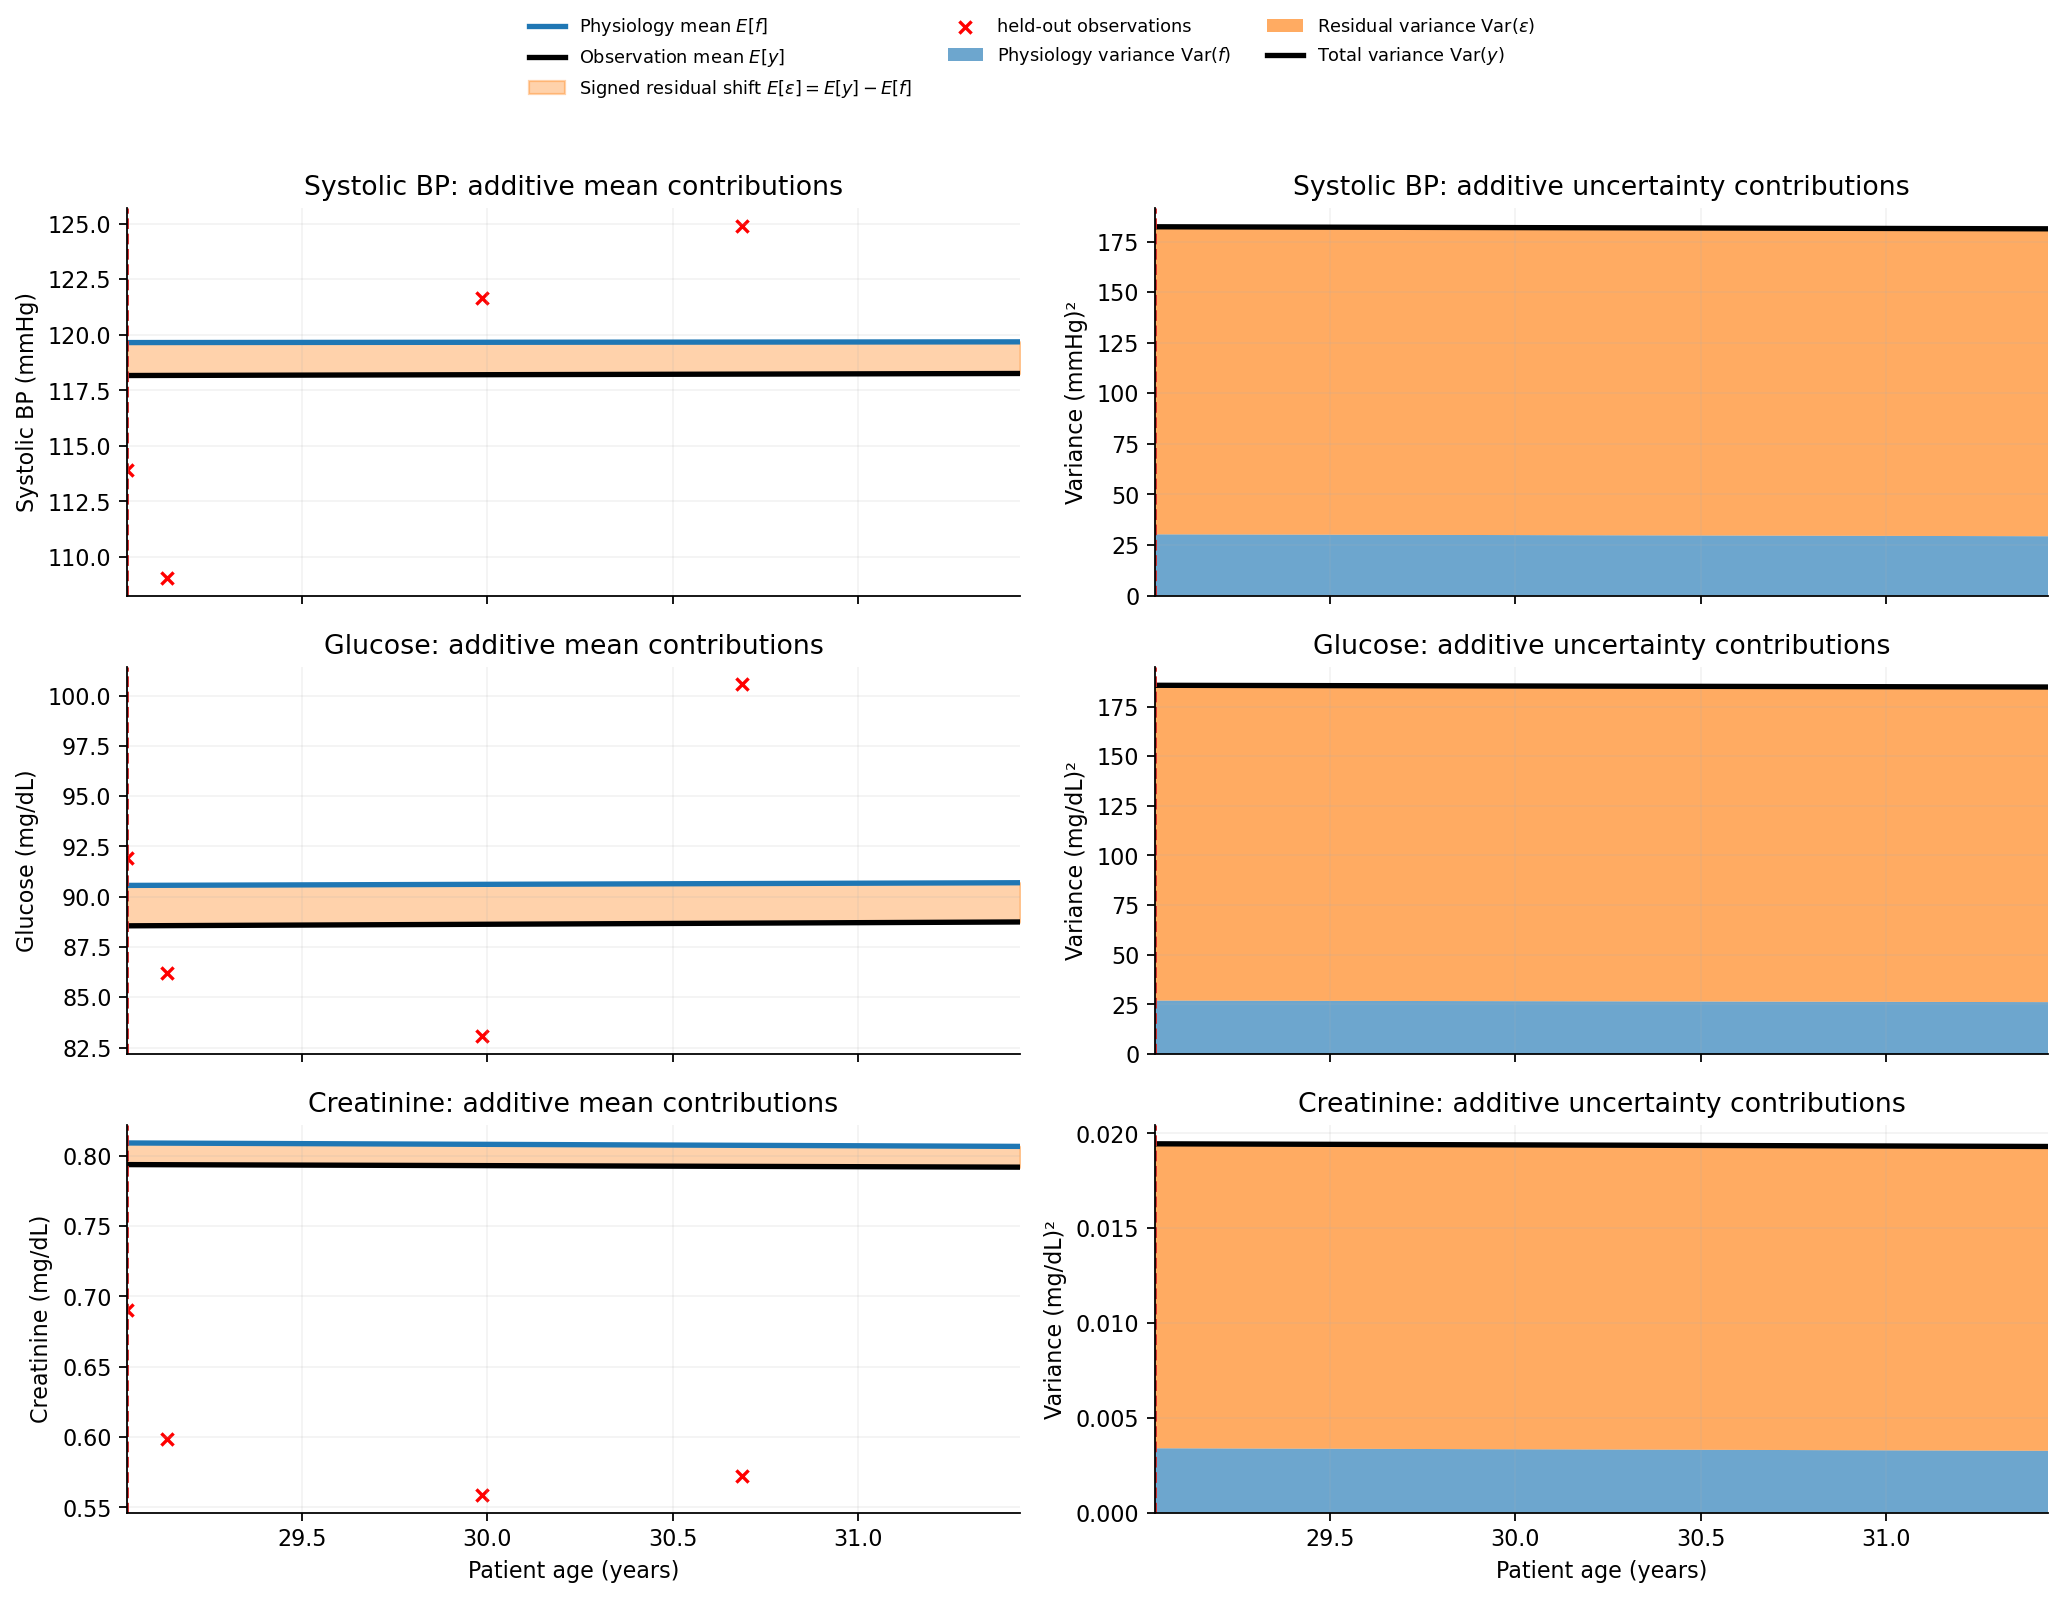

In [6]:
from lifetime_clinical.visualization.gp import plot_additive_contributions
future_age_grid=np.linspace(cutoff_age,hi,250)
plot_additive_contributions(gp_c,conditioning,heldout,future_age_grid,cutoff_age)
plt.show()
